# 06 · Probability stress cases — understand before adding rules

**Goal:** explain extreme model–market disagreement, correct the handling of elapsed
time in volatility, and check what we lose as well as what we avoid. This is a small,
repeatable **development case bench**, not another parameter grid or proof of profit.

The two frozen hold-to-resolution configurations stay fixed: **2¢ / 30–150 s** and
**5¢ / 30–240 s**, $5 intended debit, one attempt, no retries/exits/re-entry. Research
overlays are labelled separately and are not enabled in live configurations.

Follow this order:
1. Inspect the frozen case list, including ordinary winners/losses and large-gap winners.
2. Reconstruct the two live losses from their saved evidence; distinguish entry-time
   disagreement from a larger disagreement that occurred after the position was held.
3. Verify the elapsed-time calculation with deterministic examples and tests.
4. Replay **only these recorded cases**, both configurations, with three named variants.
5. Inspect avoided losses, lost winners, delayed/new trades, and readiness skips.
6. Decide on a hypothesis; freeze it before broader development testing and untouched evaluation.

The short PolyBolt/RTDS comparison was encouraging about matching values. We defer
further channel work; a 45-second observation is not a long-run reliability certificate.

In [ ]:
from pathlib import Path
import sys
import json
import pandas as pd
from IPython.display import display

REPO = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / 'pyproject.toml').exists())
sys.path.insert(0, str(REPO / 'src'))
from tyrex_pm.research.strategy_lab import extreme_cases as cases
from tyrex_pm.research.strategy_lab import case_runs
from tyrex_pm.research.strategy_lab.v3 import load_candidates

RUN_CASE_REPLAYS = False       # explicit launch; Run All otherwise only reads saved evidence
RECORDING_LEVEL = 'explain'     # decisions | explain (indicator state, shared with live)
DISAGREEMENT_PP = 9.0           # exploratory hypothesis, NOT a qualified live recommendation
SCENARIO = 'friction'
CONTRACT = 'replay_execution_contract_v1'   # v2 adds the live readiness gate (measured apart)
CASE_IDS = list(cases.RESEARCH_CASES)
print('Python:', sys.executable)
print('Replayable windows:', len(CASE_IDS), '| candidates: 2 | variants: 3')
print('Planned runs:', len(CASE_IDS) * 2 * 3, '| automatic launch:', RUN_CASE_REPLAYS)

## 1. Freeze the cases and their purpose

Seven **existing development warehouse windows** can be replayed through the real
strategy and execution engine. Four old live windows have compact saved evidence
only: the two losses and two smaller-gap controls. Their exact raw trade histories
were not captured by those runs, so this notebook cannot honestly replay their
volatility state, fills, or counterfactual profit.

The live losing cases were selected after seeing losses: they are diagnostic fixtures,
not an unbiased validation sample. A directionally correct large-gap observation is
also not necessarily an executable profitable entry. Keep the controls even when a
new rule makes their results less attractive.

In [2]:
inventory = cases.case_inventory()
display(inventory[['window_id', 'start_paris', 'kind', 'purpose']])
evidence = cases.samples()
display(cases.case_metrics(evidence).round(4))

,window_id,start_paris,kind,purpose
0,btc-updown-5m-1790870400,2026-10-01 18:00:00+02:00,warehouse replay,ordinary winner / Oct 1 control
1,btc-updown-5m-1791302100,2026-10-06 17:55:00+02:00,warehouse replay,ordinary winner / Oct 6 control
2,btc-updown-5m-1792077000,2026-10-15 17:10:00+02:00,warehouse replay,ordinary winner / Oct 15 control
3,btc-updown-5m-1791303300,2026-10-06 18:15:00+02:00,warehouse replay,large gap; direction correct (not necessarily ...
4,btc-updown-5m-1792085400,2026-10-15 19:30:00+02:00,warehouse replay,large disagreement; profitable baseline trade
5,btc-updown-5m-1790870700,2026-10-01 18:05:00+02:00,warehouse replay,ordinary baseline loss / Oct 1
6,btc-updown-5m-1792078800,2026-10-15 17:40:00+02:00,warehouse replay,ordinary baseline loss / Oct 15
7,btc-updown-5m-1792263300,2026-10-17 20:55:00+02:00,live evidence only,large disagreement / actual live loss
8,btc-updown-5m-1792266900,2026-10-17 21:55:00+02:00,live evidence only,large disagreement / actual live loss
9,btc-updown-5m-1792262700,2026-10-17 20:45:00+02:00,live evidence only,smaller-gap live control


,dataset,window_id,seconds,mean_gap_pp,max_gap_pp,share_above_9pp,share_above_15pp
0,corrected_live,btc-updown-5m-1792262700,80,2.6131,10.0421,0.0375,0.0000
1,corrected_live,btc-updown-5m-1792263300,84,41.6708,70.6219,0.9881,0.9286
2,corrected_live,btc-updown-5m-1792266900,84,43.3552,88.4549,0.9881,0.9167
3,corrected_live,btc-updown-5m-1792273500,84,0.2078,0.8457,0.0000,0.0000
4,v3_research,btc-updown-5m-1790870400,36,2.7711,6.0558,0.0000,0.0000
5,v3_research,btc-updown-5m-1790870700,94,5.9051,18.7681,0.2979,0.0426
6,v3_research,btc-updown-5m-1791302100,44,3.0404,10.1708,0.1364,0.0000
7,v3_research,btc-updown-5m-1791303300,67,8.5579,55.6473,0.2388,0.1642
8,v3_research,btc-updown-5m-1792077000,102,5.0991,17.3671,0.1176,0.0196
9,v3_research,btc-updown-5m-1792078800,112,5.0844,16.9149,0.1696,0.0089


## 2. Reconstruct disagreements, especially at entry

The window metrics above use **one saved sample per second, 31–150 seconds remaining**,
and available non-crossed two-sided UP quotes. They match the earlier baseline audit.
They do not cover the comparison candidate's whole 240-second entry band.

`gap_pp = 100 × |P(UP) − UP quote midpoint|`. A 9-point gap means 60% versus a 51¢
midpoint, for example. A window's average gap is retrospective and cannot be used
as an entry rule. The proposed veto uses only the current decision's probability and book.

The sensitivity band is a range from model assumptions, **not a calibrated confidence
interval**. The market is useful competing evidence, not ground truth. Examine price,
K, TWAP basis, sigma, time remaining and freshness before blaming either source.

,window_id,run,chosen_side,tau_s,p_up_point,p_up_low,p_up_high,book_implied_up,gap_at_intent_pp,would_veto_intent,threshold_pp
5,btc-updown-5m-1792262400,settlement_value_baseline_2c_150s_live_2026101...,DOWN,106.9478,0.0177,0.0000,0.2402,0.350,33.2262,True,9.0
6,btc-updown-5m-1792263300,settlement_value_baseline_2c_150s_live_2026101...,UP,148.5596,0.6364,0.3965,0.8835,0.315,32.1381,True,9.0
9,btc-updown-5m-1792266900,settlement_value_baseline_2c_150s_retry_live_2...,UP,148.5806,0.8538,0.6210,0.9891,0.295,55.8834,True,9.0
10,btc-updown-5m-1792266900,settlement_value_baseline_2c_150s_retry_live_2...,UP,143.5808,0.7315,0.5738,0.9092,0.245,48.6467,True,9.0
11,btc-updown-5m-1792272900,settlement_value_baseline_2c_150s_retry_live_2...,UP,90.9624,0.2593,0.1490,0.3414,0.105,15.4262,True,9.0
12,btc-updown-5m-1792273800,settlement_value_baseline_2c_150s_retry_live_2...,DOWN,147.6030,0.4380,0.3601,0.4862,0.535,9.6952,True,9.0
13,btc-updown-5m-1792274100,settlement_value_baseline_2c_150s_retry_live_2...,DOWN,149.5033,0.0003,0.0000,0.0055,0.055,5.4696,False,9.0


ENTER means intent: it does not prove a submitted or filled order.


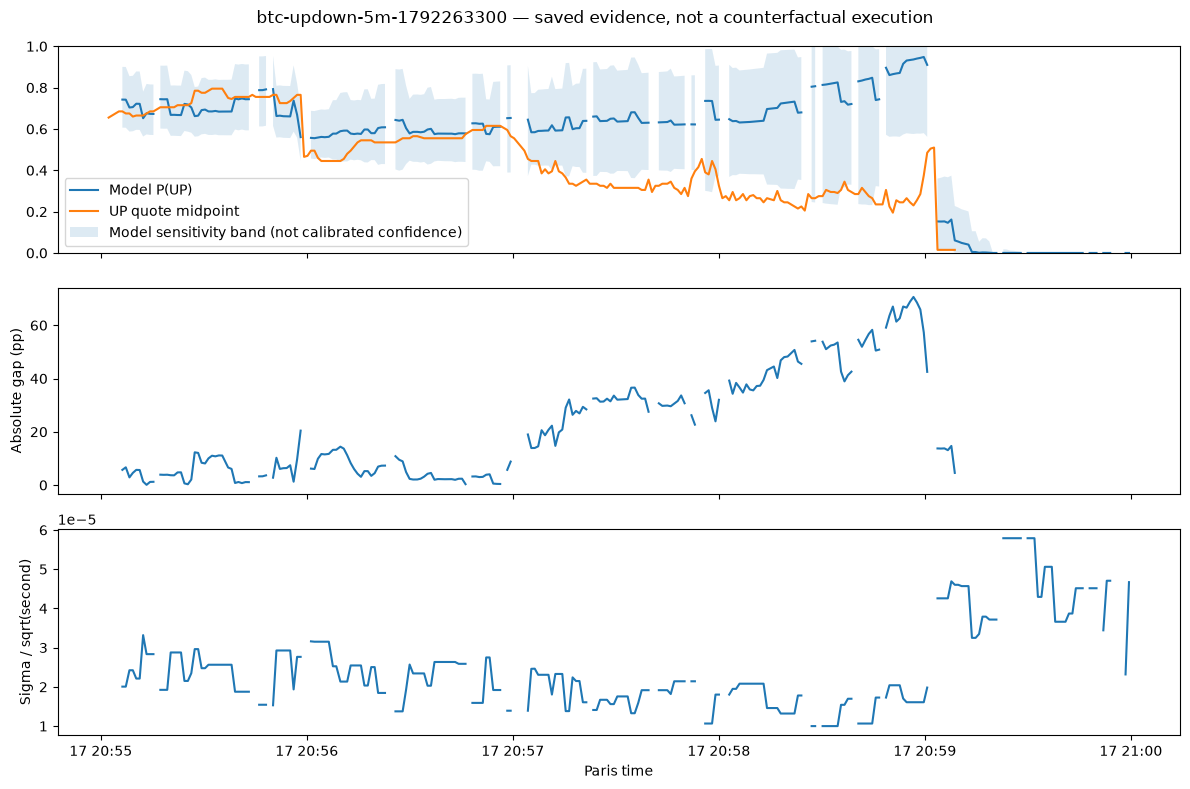

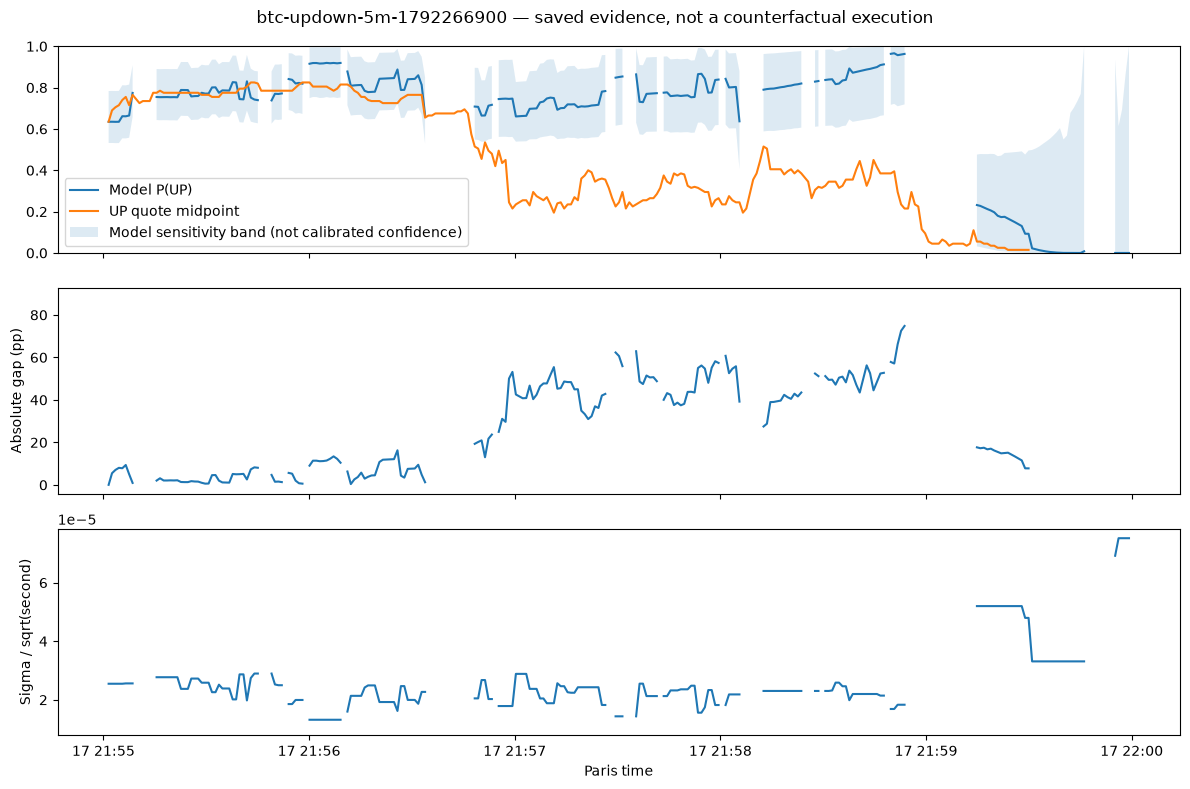

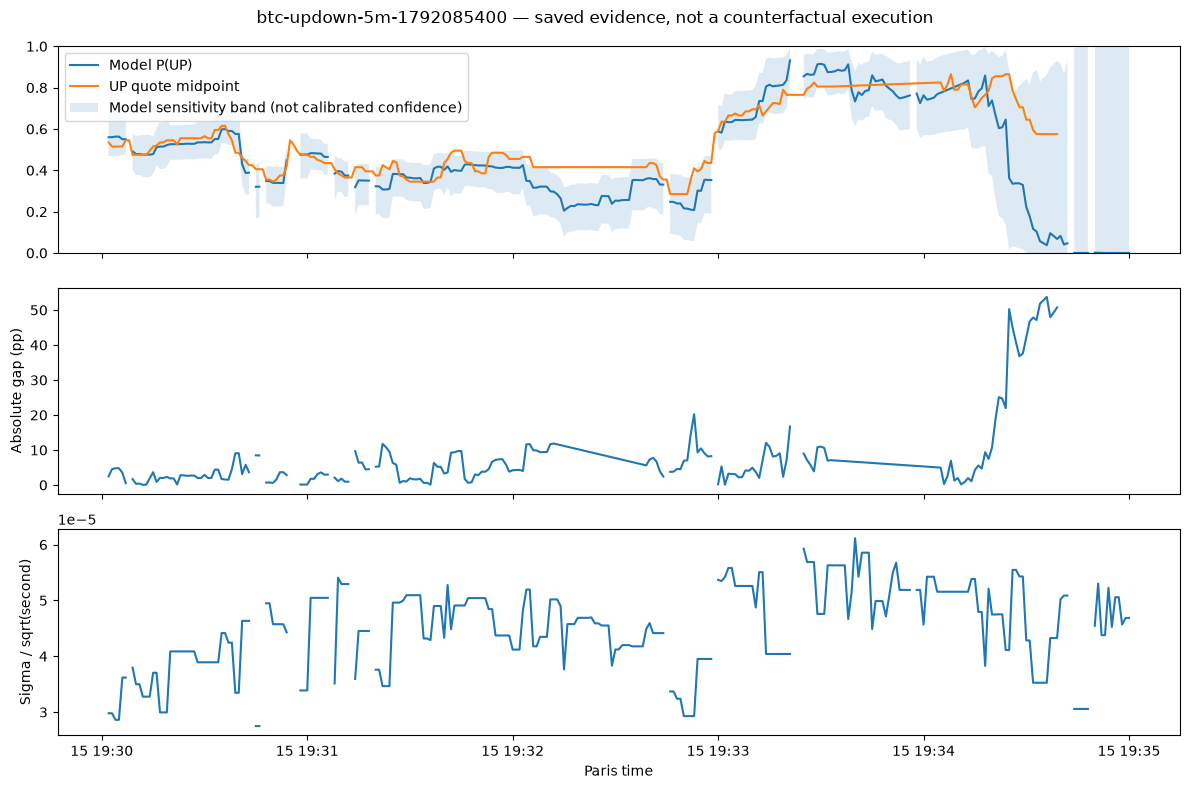

In [3]:
import matplotlib.pyplot as plt
display(cases.entry_shadow(DISAGREEMENT_PP).round(4))
print('ENTER means intent: it does not prove a submitted or filled order.')
for slug in ['btc-updown-5m-1792263300', 'btc-updown-5m-1792266900',
             'btc-updown-5m-1792085400']:
    fig = cases.plot_case(evidence, slug)
    display(fig)
    plt.close(fig)

## 3. What the time correction changes — and expected edge-case behaviour

The legacy EWMA mixes squared returns, then divides the **whole stored variance**
by the newest sample interval. A long interval can therefore abruptly lower sigma,
even though most stored information was collected at shorter intervals. Its decay
factor is also fixed per update despite a half-life expressed in seconds.

The opt-in `elapsed_variance_v1` keeps **variance per second**:

`q = log(price_new/price_old)² / dt`

`lambda(dt) = exp(-log(2) × dt / half_life_seconds)`

`v_new = lambda(dt) × v_old + (1-lambda(dt)) × q`; `sigma = sqrt(v_new)`.

It also scales the jump threshold by `sqrt(dt)` and lets unchanged observed prices
decay an already established variance. No synthetic trades are generated during a
feed outage. This is a testable estimator correction, **not proof that the resulting
probabilities are calibrated**, and not yet selected for live use.

Expected behaviours:
- Equivalent variance-rate observations at different intervals preserve the same rate.
- A flat observed price over one half-life halves established variance, subject to the floor.
- Duplicate/out-of-order ticks add no sample; all-flat bootstrap remains unready.
- Stale/missing input remains subject to the existing host freshness gates.
- A reconnect resets the feature state and retains the selected estimator policy.
- A large-gap veto waits while flat; it never consumes an attempt or sells an existing hold.
- If the gap later improves, all ordinary signal, price, size, time and risk gates must still pass.

Meaningful regression tests live in `tests/unit/research/test_extreme_cases.py`.

In [ ]:
from datetime import datetime, timezone
from decimal import Decimal
from tyrex_pm.indicators.ewma_volatility import EwmaVolatilityEstimator, SigmaConfig

probe = []
for policy in ['per_sample_v0', 'elapsed_variance_v1']:   # per_sample_v0 = the original formula
    est = EwmaVolatilityEstimator(SigmaConfig(
        variance_time_policy=policy, jump_guard=False, sigma_floor=0, min_samples_s=0))
    # Both intervals imply .0001 log-return variance per second.
    est._commit_variance(r_t=.01, dt_s=1, ts=datetime.now(timezone.utc), price=Decimal(100))
    before = est.snapshot().sigma
    est._commit_variance(r_t=.02, dt_s=4, ts=datetime.now(timezone.utc), price=Decimal(102))
    probe.append({'policy': policy, 'sigma_before': before, 'sigma_after': est.snapshot().sigma})
display(pd.DataFrame(probe))

## 4. The two frozen configurations, as strategy configuration

The variants are now **plain strategy parameters**, run through the same batch path
as every other experiment (no study hooks):

- **Unchanged:** `volatility.variance_time_policy: per_sample_v0` (the original formula),
  v3 live amount-order contract, fee reserve, pre-send gate and `reference_availability_v1`.
- **Time corrected:** only `variance_time_policy: elapsed_variance_v1` changes.
- **Time corrected + gap veto:** also `disagreement_veto: {enabled: true, max_gap_pp: DISAGREEMENT_PP}`.
  The strategy waits (`WAIT / DISAGREEMENT_VETO`) when the point probability is more than
  `max_gap_pp` points from the two-sided UP midpoint; invalid inputs give
  `DISAGREEMENT_INPUT_INVALID`. The retry clock keeps running while vetoed.

The old study recorded a veto as `BLOCKED / ENTRY_NOT_ALLOWED` on every evaluation, also
outside the entry band; the strategy veto applies where an entry could be made. Reason
labels therefore differ; behaviour (entries, fills, economics) is what the migration
check compares (`case_runs.migration_check`).

A conservative edge and a point-probability gap are different quantities. For example,
P(UP)=65%, conservative UP=55%, bid=50c and ask=52c give a 3c conservative edge
before fees, but a 14-point gap to the midpoint. A 9-point veto would block it.

Indicator state behind decisions comes from the shared recording framework
(`recording: {level: explain}`): estimator variance, last return and dt, sample count,
tape age, selected inside the entry band plus context before entries, vetoes and data
faults. The same records exist for live and observation runs.

Saved notebook 06 study bundles remain readable through `case_runs.case_frames` (legacy
adapter); new runs are written under `var/research/case_runs/`.

In [ ]:
frozen = load_candidates()
display(pd.DataFrame([{
    'candidate': name, 'edge': c.parameters['entry']['min_edge_per_share'],
    'entry_from_seconds_remaining': c.parameters['entry']['tau_max_s'],
    'entry_until_seconds_remaining': c.parameters['entry']['tau_min_s'],
    'parameter_id': c.config_id,
} for name, c in frozen.items()]))
overlays = case_runs.variant_overlays(DISAGREEMENT_PP)
display(pd.Series({k: json.dumps(v) for k, v in overlays.items()}, name='parameter overlay'))

options = dict(variants=overlays, scenario=SCENARIO, contract=CONTRACT,
               recording={'level': RECORDING_LEVEL, 'explain_trigger': 'entry_band'})
RUN_DIR = case_runs.case_run_directory(CASE_IDS, **options)
if RUN_CASE_REPLAYS:
    case_runs.run_case_set(CASE_IDS, out=RUN_DIR, **options)
RESULT_DIR = RUN_DIR if (RUN_DIR / 'summaries.parquet').exists() else (
    case_runs.latest_case_run() or case_runs.LEGACY_BUNDLE)
print('Reading:', RESULT_DIR)
if not RUN_CASE_REPLAYS:
    print('Replays disarmed. Set RUN_CASE_REPLAYS=True and rerun this cell to launch/resume.')

## 5. Did the unchanged path reproduce, and what did each change remove?

Use per-window rows before totals. A lower loss count is not automatically an improvement
if the rule discards valuable winners. The veto may delay an entry, change its side,
or lead to no entry; use these **closed-loop** results rather than subtracting old losses
from baseline P&L. The outcomes here retain the warehouse's **proxy labels**.

`vetoed_evaluations` counts evaluations (including warm-up), not lost executable trades.
`entry_attempts`/`entry_posts` and actual fills explain what happened next.

In [ ]:
frames = case_runs.case_frames(RESULT_DIR)
print('Source:', frames['source'].iloc[0].to_dict())
results = frames['summaries']
display(results[['window_id', 'candidate', 'variant', 'filled', 'side', 'entry_tau_s',
                 'realized_pnl', 'entry_attempts', 'entry_posts', 'vetoed_evaluations']]
        .sort_values(['window_id', 'candidate', 'variant']))
totals = results.groupby(['candidate', 'variant']).agg(
    windows=('slug', 'size'), fills=('filled', 'sum'), proxy_pnl=('realized_pnl', 'sum'))
wins = results.assign(win=results.filled & results.realized_pnl.gt(0)).groupby(
    ['candidate', 'variant']).win.sum()
totals['wins'] = wins
totals['win_rate'] = wins / totals.fills.replace(0, float('nan'))
display(totals)
previous = cases.previous_comparison(results)
previous['same_fill'] = previous.filled_now.eq(previous.filled_previous)
previous['same_side'] = previous.side_now.fillna('').eq(previous.side_previous.fillna(''))
previous['same_debit'] = (previous.debit_now.fillna(0) - previous.debit_previous.fillna(0)).abs() < 1e-9
previous['same_pnl'] = (previous.realized_pnl_now.fillna(0) - previous.realized_pnl_previous.fillna(0)).abs() < 1e-9
display(previous[['slug', 'candidate', 'same_fill', 'same_side', 'same_debit', 'same_pnl']])
print('Complete:', len(results) == len(CASE_IDS) * 2 * 3)

# Migration evidence (study hooks -> strategy configuration), if it has been run:
for report in sorted((case_runs.CASE_RUNS / 'migration_20261019').glob('migration_*.json')):
    rows = pd.DataFrame(json.loads(report.read_text('utf-8'))['rows'])
    trading = rows.same_entries & rows.same_fills & rows.economics_differences.map(lambda d: not d)
    print(report.name, '| trading equal (entries, fills, economics):', int(trading.sum()), '/',
          len(rows), '| every decision class equal:', int(rows.behaviour_equal.sum()), '/', len(rows))
    print('  Class differences are expected for the veto variant: the study vetoed every',
          'evaluation over the gap; the strategy veto applies only where an entry is possible.')

## 6. Inspect one run's decisions and indicator explanations

Change the case, candidate and variant below. Look at entry-time diagnostics first;
then inspect the later path. Explanations show the calculated state available at that
evaluation (from the recording framework), not future settlement information. A
post-entry disagreement does not retroactively justify preventing the earlier entry.

In [ ]:
INSPECT_CASE = 'btc-updown-5m-1792085400'
INSPECT_CANDIDATE = 'default'
INSPECT_VARIANT = 'time_corrected_gap_veto'

tag = f'{INSPECT_CASE}--{INSPECT_CANDIDATE}--{INSPECT_VARIANT}'
trace = frames['decisions']
trace = trace[trace.tag.eq(tag)] if not trace.empty else trace
if trace.empty:
    print('This result is not saved yet.')
else:
    keys = ['at_ns', 'tau_s', 'action', 'reason', 'decision_class', 'p_up_point',
            'p_up_low', 'p_up_high', 'book_implied_up', 'up_bid', 'up_ask', 'sigma',
            'disagreement_gap_pp']
    display(trace.reindex(columns=keys).tail(20))
    explained = frames['explanations']
    explained = explained[explained.tag.eq(tag)] if not explained.empty else explained
    if explained.empty:
        print('No indicator explanations (legacy bundle, or recording level below explain).')
    else:
        entry = explained[explained.action.eq('ENTER')]
        selected = (entry if not entry.empty else explained).iloc[0]
        print('at_ns', selected.at_ns, '| tau_s', selected.tau_s, '|', selected.action,
              selected.reason)
        display(pd.DataFrame(json.loads(selected.indicators)).T)

## 7. What must happen before changing live

1. **Pass the math/invariant tests and unchanged-path regression first.** If these fail,
   interpretation stops; a profit change cannot excuse an implementation error.
2. **Explain case-level effects.** Which losses were prevented, which winners were lost,
   which entries merely delayed? Do not call the rule successful from aggregate P&L alone.
3. **Capture the next rare live case properly in observation.** Existing compact logs cannot
   prove the corrected estimator would have fixed the two old live losses. Full live trace
   and raw trade/reference arrivals need their own integration and a bounded retention policy.
4. **Freeze the estimator and any proposed gate, then test beyond this hand-picked set.**
   Reuse broader development windows before one untouched evaluation; do not reuse these
   development cases as final qualification. Use all available outcomes, not only losers.
5. **Observe/paper-test the exact policy before another real-money change.** Execution,
   ownership and accounting fixes are independent of probability qualification.

The entry veto is **waiting for an acceptable signal**, not an order retry. If it clears
later, the strategy may enter only while its ordinary rules still pass. There is no
guarantee that a later entry is available, cheaper, or safer. Retry remains a separate
feature for an actual attempt that was not sent or has a definitively known outcome.

**Status:** case bench and optional research traces implemented; corrected estimator and
9-point gate experimental; neither qualified nor enabled for live. Notebook 04/05 and
their saved experiments are preserved. This notebook launches no live orders.